<a href="https://colab.research.google.com/github/thakurdisha827-coder/disha/blob/main/Aiml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# PR1: Smart Home Intelligent Agent

class SmartHomeAgent:
    def __init__(self):
        self.light = "OFF"
        self.ac = "OFF"
        self.alarm = "OFF"

    # Read sensor inputs and choose actions
    def perceive(self, temperature, light_level, motion_detected):
        # Turn on the AC if the room is hot
        if temperature > 30:
            self.ac = "ON"
        else:
            self.ac = "OFF"

        # Turn on the light if the room is dark
        if light_level < 40:
            self.light = "ON"
        else:
            self.light = "OFF"

        # Turn on the alarm if no motion is detected
        if motion_detected:
            self.alarm = "OFF"
        else:
            self.alarm = "ON"

    # Display the agent's actions
    def display_status(self):
        print("\n----- SMART HOME STATUS -----")
        print("Light           :", self.light)
        print("Air Conditioner :", self.ac)
        print("Security Alarm  :", self.alarm)


# Create the intelligent agent
agent = SmartHomeAgent()

# Get sensor inputs
temperature = float(input("Enter temperature (°C): "))
light_level = int(input("Enter light intensity (0-100): "))
motion_input = input("Is motion detected? (yes/no): ").strip().lower()

# Convert yes/no input to True/False
motion_detected = motion_input == "yes"

# Let the agent perceive the inputs and act
agent.perceive(temperature, light_level, motion_detected)

# Display the agent's actions
agent.display_status()

Enter temperature (°C): 32
Enter light intensity (0-100): 25
Is motion detected? (yes/no): yes

----- SMART HOME STATUS -----
Light           : ON
Air Conditioner : ON
Security Alarm  : OFF


In [ ]:
import heapq

# Graph with edge costs
graph = {
    'S': {'A': 1, 'B': 2},
    'A': {'C': 2},
    'B': {'D': 2},
    'C': {'G': 2},
    'D': {'G': 10},
    'G': {}
}

# Heuristic values
heuristic = {
    'S': 4,
    'A': 4,
    'B': 2,
    'C': 2,
    'D': 1,
    'G': 0
}


# Greedy Best First Search
def greedy_best_first(start, goal):
    pq = [(heuristic[start], start, [start])]
    visited = set()

    while pq:
        h, node, path = heapq.heappop(pq)

        if node in visited:
            continue

        visited.add(node)

        if node == goal:
            return path, len(visited)

        for neighbor in graph[node]:
            if neighbor not in visited:
                heapq.heappush(
                    pq,
                    (heuristic[neighbor], neighbor,
                     path + [neighbor])
                )

    return None, len(visited)


# A* Search
def a_star(start, goal):
    pq = [(heuristic[start], 0, start, [start])]
    g_cost = {start: 0}
    visited = set()

    while pq:
        f, g, node, path = heapq.heappop(pq)

        if g > g_cost.get(node, float('inf')):
            continue

        if node in visited:
            continue

        visited.add(node)

        if node == goal:
            return path, g, len(visited)

        for neighbor, cost in graph[node].items():
            new_g = g + cost

            if new_g < g_cost.get(neighbor, float('inf')):
                g_cost[neighbor] = new_g
                new_f = new_g + heuristic[neighbor]

                heapq.heappush(
                    pq,
                    (new_f, new_g, neighbor,
                     path + [neighbor])
                )

    return None, float('inf'), len(visited)


# Main Program
start = 'S'
goal = 'G'

print("Greedy Best First Search:")
path, count = greedy_best_first(start, goal)
print("Path:", path)
if path:
    cost = sum(graph[path[i]][path[i+1]]
               for i in range(len(path)-1))
    print("Total Cost:", cost)
print("Nodes Visited:", count)

print("\nA* Search:")
path, cost, count = a_star(start, goal)
print("Path:", path)
print("Total Cost:", cost)
print("Nodes Visited:", count)


Greedy Best First Search:
Path: ['S', 'B', 'D', 'G']
Total Cost: 14
Nodes Visited: 4

A* Search:
Path: ['S', 'A', 'C', 'G']
Total Cost: 5
Nodes Visited: 6


In [ ]:
print("======================================")
print("       STUDENT EXPERT SYSTEM")
print("======================================")

# Taking student information
attendance = int(input("Enter attendance percentage: "))
marks = int(input("Enter exam marks: "))

# Knowledge Base (Facts)
facts = {
    "good_attendance": attendance >= 75,
    "passing_marks": marks >= 40
}

# Rule Base
rules = {
    "eligible_for_exam": ["good_attendance"],
    "student_pass": ["passing_marks", "good_attendance"]
}

# Forward Chaining
def forward_chaining(facts, rules):
    print("\n--- FORWARD CHAINING ---")

    for rule, conditions in rules.items():
        if all(facts.get(condition, False) for condition in conditions):
            facts[rule] = True
            print(rule, "is TRUE")
        else:
            facts[rule] = False
            print(rule, "is FALSE")

    return facts

# Backward Chaining
def backward_chaining(goal, facts, rules):
    if goal in facts:
        return facts[goal]

    if goal in rules:
        conditions = rules[goal]

        for condition in conditions:
            if not backward_chaining(condition, facts, rules):
                return False

        return True

    return False

# Execute Forward Chaining
facts = forward_chaining(facts, rules)

# Execute Backward Chaining
print("\n--- BACKWARD CHAINING ---")

goal = "student_pass"

if backward_chaining(goal, facts, rules):
    print("Goal achieved: Student is eligible to pass.")
else:
    print("Goal not achieved: Student is not eligible to pass.")

print("\nProgram executed successfully!")

       STUDENT EXPERT SYSTEM
Enter attendance percentage: 75
Enter exam marks: 70

--- FORWARD CHAINING ---
eligible_for_exam is TRUE
student_pass is TRUE

--- BACKWARD CHAINING ---
Goal achieved: Student is eligible to pass.

Program executed successfully!


Dataset Loaded Successfully
Original Dataset Shape: (569, 30)

Features Before PCA: 30
Features After PCA: 2

Explained Variance Ratio:
[0.44413492 0.18944618]
Total Variance Preserved: 0.6335811006772492

Performance Before PCA
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1-Score: 0.9861111111111112

Performance After PCA
Accuracy: 0.9473684210526315
Precision: 0.9714285714285714
Recall: 0.9444444444444444
F1-Score: 0.9577464788732394


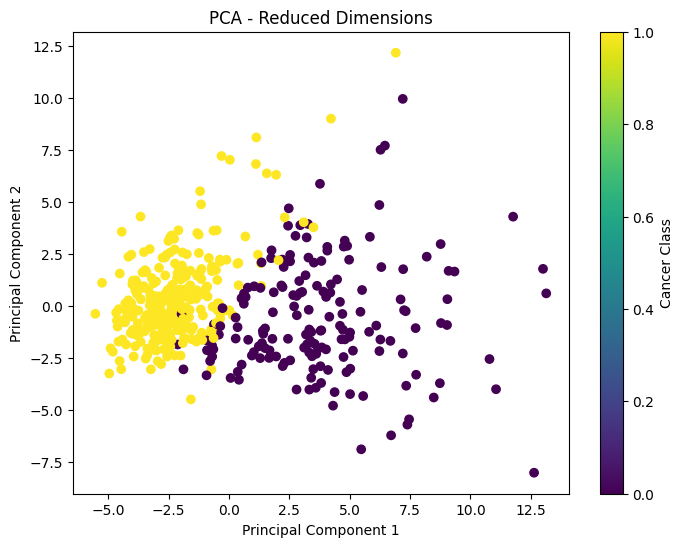

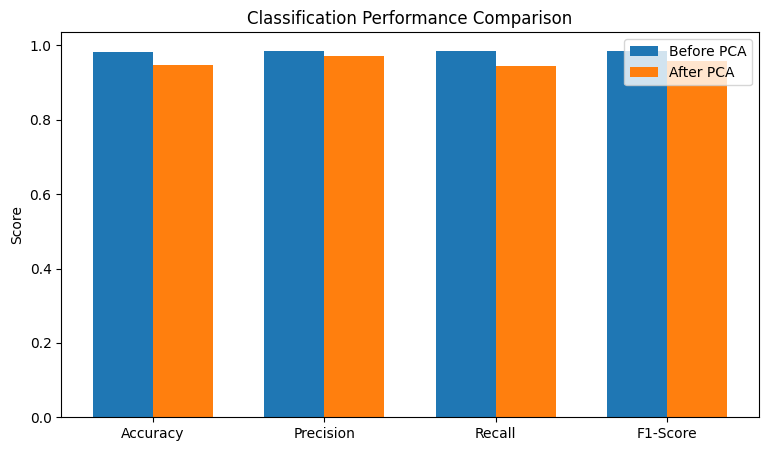


PCA Implementation Completed Successfully!


In [ ]:
# Practical 10: Dimensionality Reduction using PCA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Load Dataset
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Loaded Successfully")
print("Original Dataset Shape:", X.shape)

# 2. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Classification Before PCA
model1 = LogisticRegression(max_iter=5000)

model1.fit(X_train_scaled, y_train)

pred1 = model1.predict(X_test_scaled)

accuracy1 = accuracy_score(y_test, pred1)

# 5. Apply PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("\nFeatures Before PCA:", X.shape[1])
print("Features After PCA:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Preserved:",
      sum(pca.explained_variance_ratio_))

# 6. Classification After PCA
model2 = LogisticRegression(max_iter=5000)

model2.fit(X_train_pca, y_train)

pred2 = model2.predict(X_test_pca)

accuracy2 = accuracy_score(y_test, pred2)

# 7. Evaluation Before PCA
print("\nPerformance Before PCA")
print("Accuracy:", accuracy1)
print("Precision:", precision_score(y_test, pred1))
print("Recall:", recall_score(y_test, pred1))
print("F1-Score:", f1_score(y_test, pred1))

# 8. Evaluation After PCA
print("\nPerformance After PCA")
print("Accuracy:", accuracy2)
print("Precision:", precision_score(y_test, pred2))
print("Recall:", recall_score(y_test, pred2))
print("F1-Score:", f1_score(y_test, pred2))

# 9. Visualization of Reduced Dimensions
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap='viridis'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Reduced Dimensions")
plt.colorbar(label="Cancer Class")
plt.show()

# 10. Performance Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

before = [
    accuracy_score(y_test, pred1),
    precision_score(y_test, pred1),
    recall_score(y_test, pred1),
    f1_score(y_test, pred1)
]

after = [
    accuracy_score(y_test, pred2),
    precision_score(y_test, pred2),
    recall_score(y_test, pred2),
    f1_score(y_test, pred2)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before, width, label='Before PCA')
plt.bar(x + width/2, after, width, label='After PCA')

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Classification Performance Comparison")
plt.legend()
plt.show()

print("\nPCA Implementation Completed Successfully!")